In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [8]:
df = pd.read_csv('/content/diabetes (6).csv')

print("Dataset loaded successfully")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [9]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nOutcome Distribution:")
print(df['Outcome'].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Outcome Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [10]:
df = df.copy()

cols = [
    'Glucose', 'BloodPressure',
    'SkinThickness', 'Insulin', 'BMI'
]

df[cols] = df[cols].replace(0, np.nan)
df[cols] = df[cols].fillna(df[cols].median())

print("Missing values after preprocessing:")
print(df.isnull().sum())

Missing values after preprocessing:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [11]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (768, 8)
Target shape: (768,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 614
Testing samples: 154


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed")

Feature scaling completed


In [14]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

print("KNN model trained successfully")

KNN model trained successfully


In [15]:
y_pred = knn.predict(X_test_scaled)

print("Actual values:")
print(y_test.values[:10])

print("\nPredicted values:")
print(y_pred[:10])

Actual values:
[0 0 0 1 0 0 1 1 0 0]

Predicted values:
[1 0 0 1 0 0 0 1 0 1]


In [16]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("KNN Model Evaluation")
print("--------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1 Score:", round(f1, 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

KNN Model Evaluation
--------------------
Accuracy: 75.32 %
Precision: 0.66
Recall: 0.611
F1 Score: 0.635

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



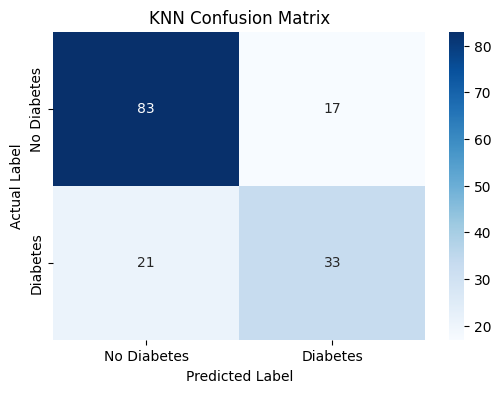

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('KNN Confusion Matrix')
plt.show()

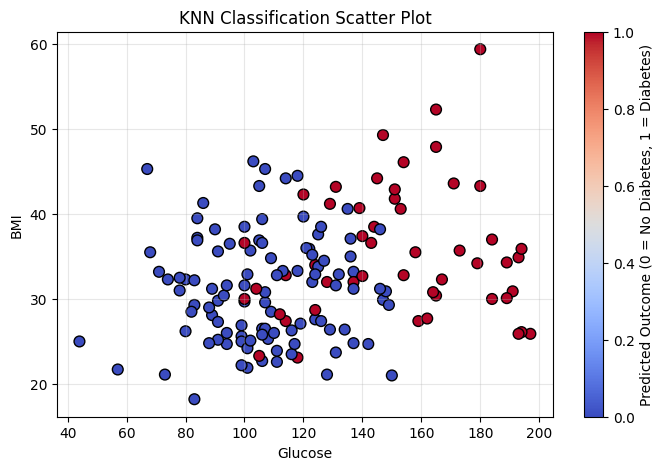

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test['Glucose'],
    X_test['BMI'],
    c=y_pred,
    cmap='coolwarm',
    s=60,
    edgecolors='black'
)

plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.title('KNN Classification Scatter Plot')
plt.colorbar(label='Predicted Outcome (0 = No Diabetes, 1 = Diabetes)')
plt.grid(True, alpha=0.3)
plt.show()

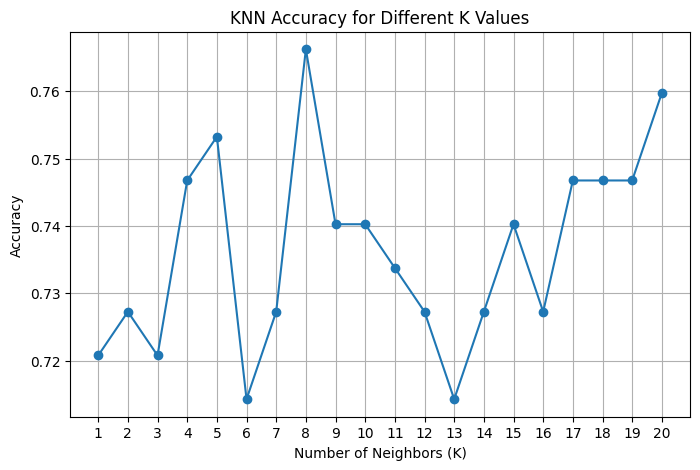

Best K value: 8
Highest test accuracy: 76.62 %


In [18]:
k_values = range(1, 21)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, predictions))

plt.figure(figsize=(8, 5))

plt.plot(k_values, accuracies, marker='o')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy for Different K Values')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

best_k = list(k_values)[np.argmax(accuracies)]

print("Best K value:", best_k)
print("Highest test accuracy:", round(max(accuracies) * 100, 2), "%")

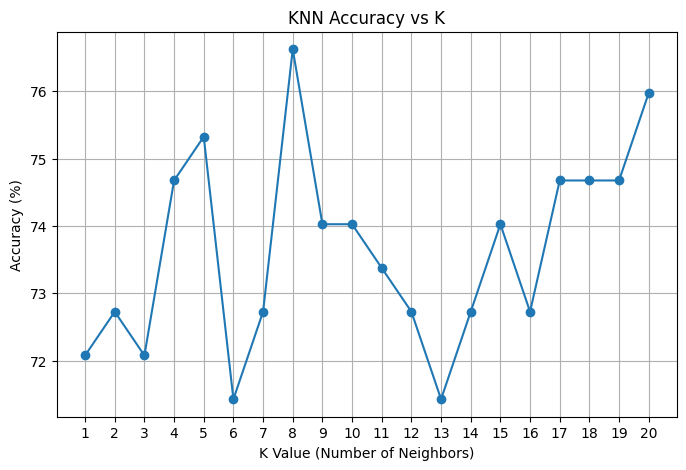

Best K: 8
Highest Accuracy: 76.62 %


In [23]:
k_values = range(1, 21)
accuracy_values = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    y_pred_k = knn.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred_k)

    accuracy_values.append(accuracy * 100)

# Plot Accuracy vs K
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracy_values, marker='o')

plt.xlabel('K Value (Number of Neighbors)')
plt.ylabel('Accuracy (%)')
plt.title('KNN Accuracy vs K')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Display best K
best_k = list(k_values)[accuracy_values.index(max(accuracy_values))]
print("Best K:", best_k)
print("Highest Accuracy:", round(max(accuracy_values), 2), "%")

In [19]:
best_knn = KNeighborsClassifier(n_neighbors=best_k)

best_knn.fit(X_train_scaled, y_train)

final_predictions = best_knn.predict(X_test_scaled)

print("Final KNN Accuracy:",
      round(accuracy_score(y_test, final_predictions) * 100, 2), "%")

Final KNN Accuracy: 76.62 %


In [20]:
results = pd.DataFrame({
    'Actual Outcome': y_test.values,
    'Predicted Outcome': final_predictions
})

display(results.head(20))

,Actual Outcome,Predicted Outcome
0,0,1
1,0,0
2,0,0
3,1,0
4,0,0
5,0,0
6,1,0
7,1,1
8,0,0
9,0,1


In [24]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create KNN classifier
knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)

# Train the model
knn.fit(X_train_scaled, y_train)

# Make predictions
y_pred = knn.predict(X_test_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("K-Neighbors Classifier")
print("Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

K-Neighbors Classifier
Accuracy: 75.32 %

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [21]:
results.to_csv('/content/knn_diabetes_predictions.csv', index=False)

print("Predictions saved successfully!")

Predictions saved successfully!
